# Concept based Mini Project:
## Spam Email Classification using NLP and ML

In [1]:
# let us import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/raghunandanms/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [3]:
spam = pd.read_csv('Lab 30 spam.csv')
messages = [line.rstrip() for line in spam]
print(len(messages))

2


In [4]:
spam.head(10)

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [5]:
spam.describe()

,Category,Message
count,5572,5572
unique,2,5157
top,ham,"Sorry, I'll call later"
freq,4825,30


In [6]:
spam['length'] = spam['Message'].apply(len)
spam.head()

,Category,Message,length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


<Axes: ylabel='Frequency'>

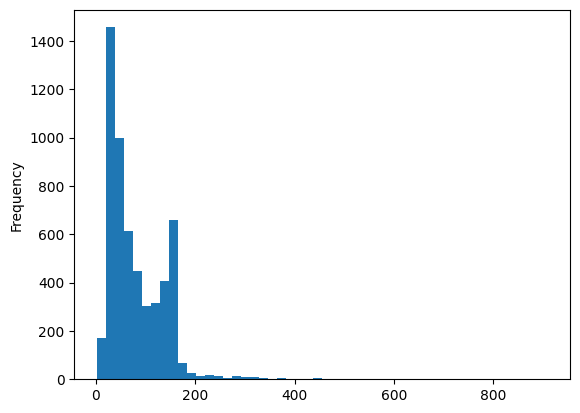

In [8]:
spam['length'].plot(bins=50, kind='hist')

<Axes: xlabel='length', ylabel='Count'>

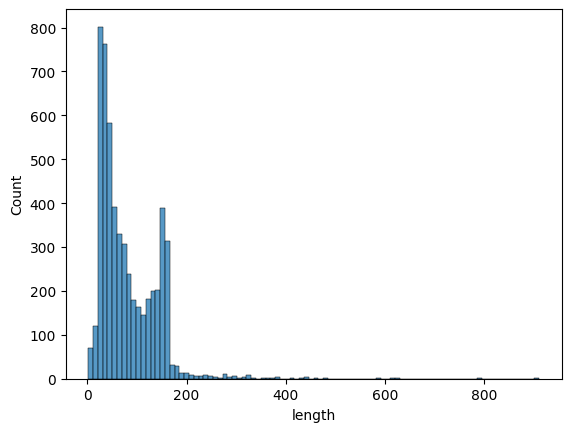

In [9]:
sns.histplot(spam['length'])

In [10]:
# preprocessing
from nltk.corpus import stopwords
def text_process(msg):
    no_punc = [char for char in msg if char not in string.punctuation]
    no_punc = ''.join(no_punc)
    return [word for word in no_punc.split() if word.lower() 
            not in stopwords.words('english')]

In [11]:
spam['Message'].head().apply(text_process)

0    [Go, jurong, point, crazy, Available, bugis, n...
1                       [Ok, lar, Joking, wif, u, oni]
2    [Free, entry, 2, wkly, comp, win, FA, Cup, fin...
3        [U, dun, say, early, hor, U, c, already, say]
4    [Nah, dont, think, goes, usf, lives, around, t...
Name: Message, dtype: object

In [12]:
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
stemmer = PorterStemmer()

In [13]:
msg_stem = """The crew of the USS Discovery discovered many discoveries.
Discovering is what explorers do."""

In [14]:
words = word_tokenize(msg_stem)
print(words)

['The', 'crew', 'of', 'the', 'USS', 'Discovery', 'discovered', 'many', 'discoveries', '.', 'Discovering', 'is', 'what', 'explorers', 'do', '.']


In [15]:
stem_words = [stemmer.stem(word) for word in words]
stem_words

['the',
 'crew',
 'of',
 'the',
 'uss',
 'discoveri',
 'discov',
 'mani',
 'discoveri',
 '.',
 'discov',
 'is',
 'what',
 'explor',
 'do',
 '.']

In [16]:
from sklearn.feature_extraction.text import CountVectorizer
bow_transform = CountVectorizer(analyzer=text_process).fit(spam['Message'])
print(len(bow_transform.vocabulary_))

11422


In [18]:
msg4 = spam['Message'][3]
msg4

'U dun say so early hor... U c already then say...'

In [19]:
bow4 = bow_transform.transform([msg4])
print(bow4)
print(bow4.shape)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 7 stored elements and shape (1, 11422)>
  Coords	Values
  (0, 4066)	2
  (0, 4627)	1
  (0, 5258)	1
  (0, 6201)	1
  (0, 6219)	1
  (0, 7183)	1
  (0, 9551)	2
(1, 11422)


In [24]:
messages_bow = bow_transform.transform(spam['Message'])

print('Shape of Sparse Matrix:', messages_bow.shape)
print('Amount of Non Zero Occurence:', messages_bow.nnz)
print('Sparsity Value:', 
      (100.0 * messages_bow.nnz / (messages_bow.shape[0] * messages_bow.shape[1])))

Shape of Sparse Matrix: (5572, 11422)
Amount of Non Zero Occurence: 50500
Sparsity Value: 0.07934838914285262


In [ ]:
# TF-IDF term freq - inv doc freq